# 01 — Exploratory data analysis

Sales charts use history through d_1913; event, SNAP, and price associations are descriptive.

## Imports

In [1]:
from pathlib import Path
from types import SimpleNamespace
import os, json, time, warnings
import numpy as np
import pandas as pd
from IPython.display import display


In [2]:
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / 'data/calendar.csv').exists())
DATA = ROOT / 'data'
OUT = DATA / 'processed'
RESULTS = ROOT / 'reports/results'
FIGURES = ROOT / 'reports/figures'
for folder in [OUT, RESULTS, FIGURES]:
    folder.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(ROOT / '.venv/matplotlib'))


'/Users/moha/Machine-Learning-Project/Project 1/.venv/matplotlib'

In [3]:
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi':100, 'axes.spines.top':False, 'axes.spines.right':False})
COLORS = ['#2563eb', '#059669', '#ea580c', '#7c3aed']


## Calendar

In [4]:
calendar = pd.read_csv(DATA / 'calendar.csv', parse_dates=['date'])
calendar['day'] = calendar.d.str.removeprefix('d_').astype(int)
calendar = calendar.sort_values('day').reset_index(drop=True)
weeks = pd.Index(sorted(calendar.wm_yr_wk.unique()))
calendar['week_index'] = weeks.get_indexer(calendar.wm_yr_wk)
assert calendar.day.tolist() == list(range(1, len(calendar)+1))
assert calendar.date.diff().dropna().eq(pd.Timedelta(days=1)).all()
display(calendar.head())


,date,wm_yr_wk,weekday,wday,month,year,d,event_name_1,event_type_1,event_name_2,event_type_2,snap_CA,snap_TX,snap_WI,day,week_index
0,2011-01-29,11101,Saturday,1,1,2011,d_1,NaN,NaN,NaN,NaN,0,0,0,1,0
1,2011-01-30,11101,Sunday,2,1,2011,d_2,NaN,NaN,NaN,NaN,0,0,0,2,0
2,2011-01-31,11101,Monday,3,1,2011,d_3,NaN,NaN,NaN,NaN,0,0,0,3,0
3,2011-02-01,11101,Tuesday,4,2,2011,d_4,NaN,NaN,NaN,NaN,1,1,0,4,0
4,2011-02-02,11101,Wednesday,5,2,2011,d_5,NaN,NaN,NaN,NaN,1,0,1,5,0


## Product and store identifiers

In [5]:
META = ['id','item_id','dept_id','cat_id','store_id','state_id']
metadata = pd.read_csv(DATA / 'sales_train_validation.csv', usecols=META)
metadata['series_id'] = metadata.id.str.removesuffix('_validation')
series_index = pd.Index(metadata.series_id)
assert series_index.is_unique
assert not metadata.duplicated(['store_id','item_id']).any()
assert not metadata.isna().any().any()


## Validation sales

In [6]:
header = pd.read_csv(DATA / 'sales_train_validation.csv', nrows=0).columns
day_columns = [c for c in header if c.startswith('d_')]
assert day_columns == [f'd_{i}' for i in range(1,len(day_columns)+1)]
values = pd.read_csv(DATA / 'sales_train_validation.csv',
                     usecols=day_columns, dtype='float32').to_numpy()
assert np.isfinite(values).all() and (values >= 0).all()
assert (values == np.floor(values)).all() and values.max() <= 65535
sales = values.astype('uint16')
del values


## Overlapping sales history

In [7]:
evaluation_days = [c for c in pd.read_csv(DATA / 'sales_train_evaluation.csv', nrows=0)
                   if c.startswith('d_')]
full_sales = np.empty((len(metadata), len(evaluation_days)), dtype='uint16')
seen = np.zeros(len(metadata), dtype=bool)


In [8]:
def validate_evaluation_chunk(chunk):
    positions = series_index.get_indexer(chunk.id.str.removesuffix('_evaluation'))
    assert (positions >= 0).all() and len(np.unique(positions)) == len(positions)
    assert not seen[positions].any()
    assert chunk[META[1:]].reset_index(drop=True).equals(
        metadata.iloc[positions][META[1:]].reset_index(drop=True))
    values = chunk[evaluation_days].to_numpy(dtype='float32')
    assert np.isfinite(values).all() and (values >= 0).all()
    assert (values == np.floor(values)).all() and values.max() <= 65535
    np.testing.assert_array_equal(values[:, :len(day_columns)], sales[positions])
    return positions, values.astype('uint16')


In [9]:
reader = pd.read_csv(DATA / 'sales_train_evaluation.csv', chunksize=1000,
                     dtype={d:'float32' for d in evaluation_days})
for chunk in reader:
    positions, values = validate_evaluation_chunk(chunk)
    full_sales[positions] = values
    seen[positions] = True
assert seen.all()
print('All overlapping sales values match after ID alignment.')
del reader, chunk, positions, values


All overlapping sales values match after ID alignment.


## Weekly prices and keys

In [10]:
price_table = pd.read_csv(DATA / 'sell_prices.csv', dtype={
    'store_id':'category', 'item_id':'category',
    'wm_yr_wk':'int32', 'sell_price':'float32'})
assert not price_table.isna().any().any()
assert (price_table.sell_price > 0).all()
assert not price_table.duplicated(['store_id','item_id','wm_yr_wk']).any()
display(price_table.head())


,store_id,item_id,wm_yr_wk,sell_price
0,CA_1,HOBBIES_1_001,11325,9.58
1,CA_1,HOBBIES_1_001,11326,9.58
2,CA_1,HOBBIES_1_001,11327,8.26
3,CA_1,HOBBIES_1_001,11328,8.26
4,CA_1,HOBBIES_1_001,11329,8.26


In [11]:
pair_index = pd.MultiIndex.from_frame(metadata[['store_id','item_id']])
price_rows = pair_index.get_indexer(pd.MultiIndex.from_frame(price_table[['store_id','item_id']]))
price_weeks = weeks.get_indexer(price_table.wm_yr_wk)
assert (price_rows >= 0).all() and (price_weeks >= 0).all()
prices = np.full((len(metadata),len(weeks)), np.nan, dtype='float32')
prices[price_rows,price_weeks] = price_table.sell_price.to_numpy()
price_count = len(price_table)
del price_rows, price_weeks, price_table


## Submission format

In [12]:
template = pd.read_csv(DATA / 'sample_submission.csv')
expected_ids = pd.concat([metadata.series_id+'_validation', metadata.series_id+'_evaluation'])
assert template.columns.tolist() == ['id', *[f'F{i}' for i in range(1,29)]]
assert template.id.is_unique and set(template.id) == set(expected_ids)
assert not template.isna().any().any()
print(template.shape)


(60980, 29)


In [13]:
validation_audit = dict(rows=len(metadata), days=sales.shape[1],
    zeros=int((sales==0).sum()), units=int(sales.sum(dtype='int64')))
audit = dict(sales={'validation':validation_audit,
    'evaluation':dict(rows=len(metadata),days=full_sales.shape[1])},
    prices=dict(rows=price_count), submission=dict(rows=len(template)))
data = SimpleNamespace(root=ROOT, sales=sales, prices=prices,
                       metadata=metadata, calendar=calendar, audit=audit)


In [14]:
def save_figure(data, name):
    plt.gcf().tight_layout()
    plt.gcf().savefig(FIGURES / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()


## File inventory

In [15]:
rows = []
counts = {"calendar.csv": len(data.calendar), "sell_prices.csv": data.audit['prices']['rows'],
          "sample_submission.csv": data.audit['submission']['rows'],
          **{f"sales_train_{phase}.csv": stats['rows'] for phase, stats in data.audit['sales'].items()}}
for path in sorted((data.root / "data").glob("*.csv")):
    rows.append(dict(file=path.name, rows=counts[path.name], columns=len(pd.read_csv(path, nrows=0).columns),
                     size_mb=round(path.stat().st_size / 1024 ** 2, 2)))
display(pd.DataFrame(rows))


,file,rows,columns,size_mb
0,calendar.csv,1969,14,0.10
1,sales_train_evaluation.csv,30490,1947,116.10
2,sales_train_validation.csv,30490,1919,114.45
3,sample_submission.csv,60980,29,4.99
4,sell_prices.csv,6841121,4,193.97


## Sales profiles and representative samples

In [16]:
cutoff = data.audit["sales"]["validation"]["days"]
sales = data.sales[:, :cutoff]
profile = data.metadata.copy()
profile["units"] = sales.sum(axis=1, dtype="int64")
profile["mean_daily"] = profile.units / cutoff
positive = (sales > 0).sum(axis=1)
profile["zero_rate"] = 1 - positive / cutoff
first = np.argmax(sales > 0, axis=1)
active = np.where(positive > 0, cutoff - first, 0)
profile["active_zero_rate"] = np.divide(active - positive, active, out=np.full(len(profile), np.nan), where=active > 0)
profile["first_sale_day"] = np.where(positive > 0, first + 1, np.nan)
daily = data.calendar.iloc[:cutoff].copy()
daily["units"] = sales.sum(axis=0, dtype="int64")


In [17]:
groups = {}
for column in ["state_id", "store_id", "cat_id", "dept_id"]:
    groups[column] = pd.DataFrame({key: sales[np.asarray(indices)].sum(axis=0, dtype="int64")
                                   for key, indices in profile.groupby(column).indices.items()}, index=daily.date)
sample_rows = []
for _, group in profile.groupby(["store_id", "cat_id"]):
    ordered = group.sort_values("units")
    sample_rows.extend([int(ordered.index[-1]), int(ordered.index[len(ordered) // 2])])
representatives = dict(high_volume=int(profile.units.idxmax()),
                       typical=int((profile.units - profile.units.median()).abs().idxmin()))
eligible = profile[(positive >= 20) & (profile.active_zero_rate > .8)]
representatives["intermittent"] = int(eligible.units.idxmax())
recent_weeks = np.unique(data.calendar.week_index.iloc[cutoff - 365:cutoff])


In [18]:
recent_prices = data.prices[:, recent_weeks]
valid_pairs = np.isfinite(recent_prices[:, 1:]) & np.isfinite(recent_prices[:, :-1])
profile['recent_price_changes'] = ((recent_prices[:, 1:] != recent_prices[:, :-1]) & valid_pairs).sum(axis=1)
for _, group in profile.groupby(['store_id', 'cat_id']):
    candidate = int(group.recent_price_changes.idxmax())
    if profile.recent_price_changes.iloc[candidate] >= 2:
        sample_rows.append(candidate)
sample_rows = sorted(set(sample_rows + list(representatives.values())))
eda = dict(cutoff=cutoff, profile=profile, daily=daily, groups=groups,
            sample_rows=sample_rows, representatives=representatives)


## Demand trends

In [19]:
daily = eda['daily'].set_index('date')


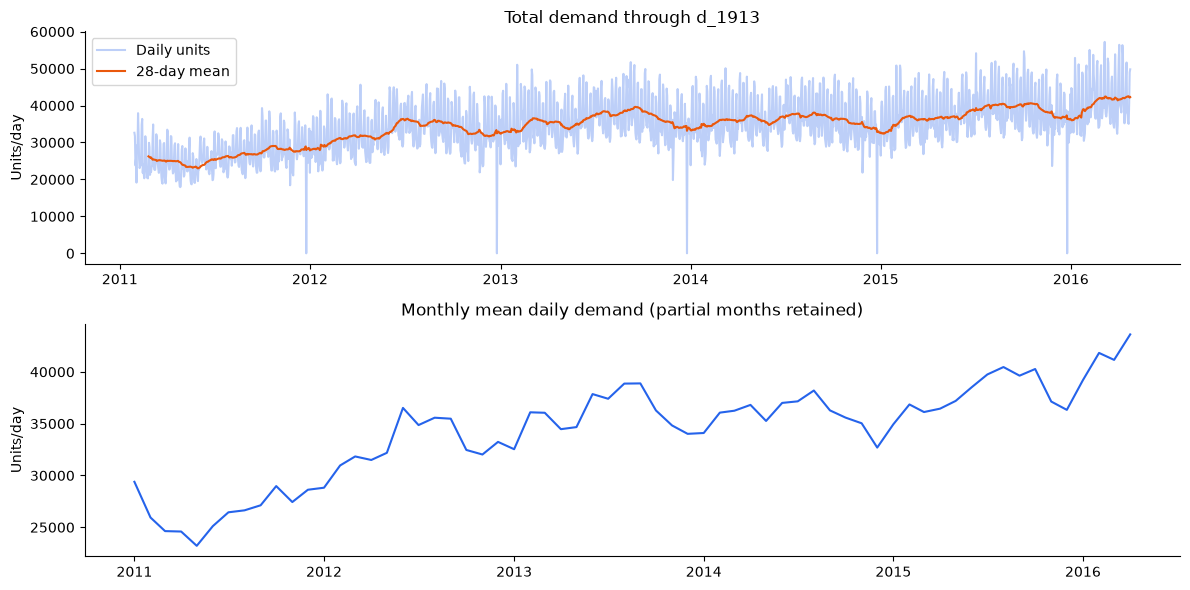

In [20]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6))
axes[0].plot(daily.index, daily.units, alpha=.3, color=COLORS[0], label='Daily units')
axes[0].plot(daily.index, daily.units.rolling(28).mean(), color=COLORS[2], label='28-day mean')
axes[0].set(title='Total demand through d_1913', ylabel='Units/day')
axes[0].legend()
monthly = daily.units.resample('MS').mean()
axes[1].plot(monthly.index, monthly, color=COLORS[0])
axes[1].set(title='Monthly mean daily demand (partial months retained)', ylabel='Units/day')
save_figure(data, 'eda_01_demand_trend')


In [21]:
display(monthly.rename('mean_daily_units').to_frame().tail(12))


,mean_daily_units
date,
2015-05-01,37194.000000
2015-06-01,38519.966667
2015-07-01,39746.677419
2015-08-01,40462.612903
2015-09-01,39630.433333
2015-10-01,40272.161290
2015-11-01,37132.533333
2015-12-01,36330.193548
2016-01-01,39202.774194


## Weekly and monthly seasonality

In [22]:
daily = eda['daily']
weekday = daily.groupby('wday').agg(weekday=('weekday', 'first'), mean_units=('units', 'mean'), days=('units', 'size'))


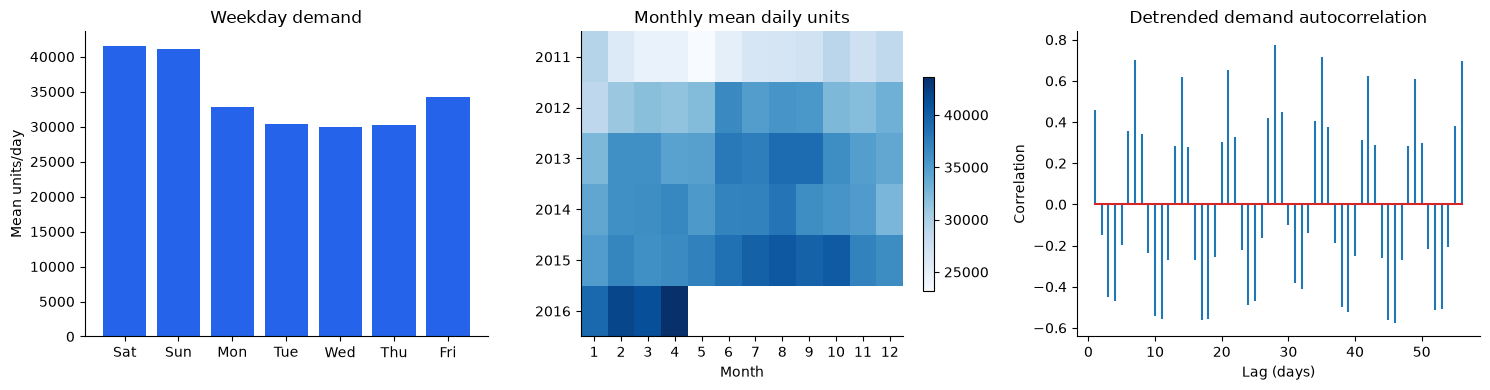

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(weekday.weekday.str[:3], weekday.mean_units, color=COLORS[0])
axes[0].set(title='Weekday demand', ylabel='Mean units/day')
monthly = daily.pivot_table(index='year', columns='month', values='units', aggfunc='mean')
image = axes[1].imshow(monthly, aspect='auto', cmap='Blues')
axes[1].set(xticks=range(len(monthly.columns)), xticklabels=monthly.columns,
            yticks=range(len(monthly.index)), yticklabels=monthly.index,
            title='Monthly mean daily units', xlabel='Month')
fig.colorbar(image, ax=axes[1], shrink=.7)
residual = daily.units - daily.units.rolling(28, center=True, min_periods=28).mean()
correlations = [residual.autocorr(lag) for lag in range(1, 57)]
axes[2].stem(range(1, 57), correlations, markerfmt=' ')
axes[2].set(title='Detrended demand autocorrelation', xlabel='Lag (days)', ylabel='Correlation')
save_figure(data, 'eda_02_seasonality')


In [24]:
eda['weekday'] = weekday
eda['acf7'] = float(residual.autocorr(7))
display(weekday)


,weekday,mean_units,days
wday,,,
1,Saturday,41546.894161,274
2,Sunday,41130.021898,274
3,Monday,32852.967033,273
4,Tuesday,30368.780220,273
5,Wednesday,30010.021978,273
6,Thursday,30205.007326,273
7,Friday,34225.985348,273


## Stores and categories

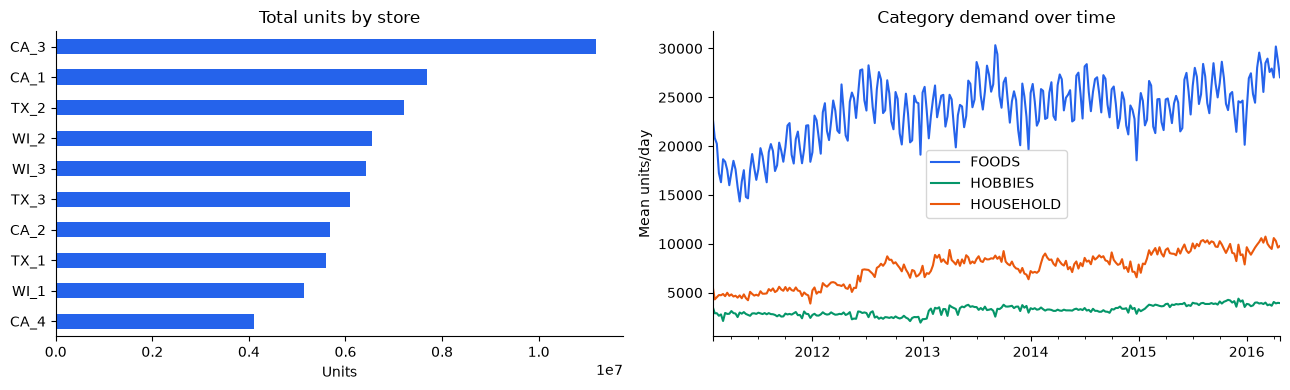

In [25]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
stores = eda['groups']['store_id'].sum().sort_values()
stores.plot.barh(ax=axes[0], color=COLORS[0])
axes[0].set(title='Total units by store', xlabel='Units', ylabel='')
categories = eda['groups']['cat_id'].resample('W').mean()
categories.plot(ax=axes[1], color=COLORS[:3])
axes[1].set(title='Category demand over time', ylabel='Mean units/day', xlabel='')
save_figure(data, 'eda_03_segments')


In [26]:
table = eda['profile'].groupby(['state_id', 'cat_id']).agg(series=('series_id', 'size'), units=('units', 'sum'),
                                                                      mean_daily_per_series=('mean_daily', 'mean'))
display(table)


series     units  mean_daily_per_series
state_id cat_id                                            
CA       FOODS        5748  19196302               1.745765
         HOBBIES      2260   3039883               0.703126
         HOUSEHOLD    4188   6439362               0.803750
TX       FOODS        4311  12956421               1.571057
         HOBBIES      1695   1592339               0.491078
         HOUSEHOLD    3141   4350246               0.723987
WI       FOODS        4311  12937216               1.568729
         HOBBIES      1695   1492578               0.460312
         HOUSEHOLD    3141   3691062               0.614283

## Zero demand and concentration

In [27]:
profile = eda['profile']


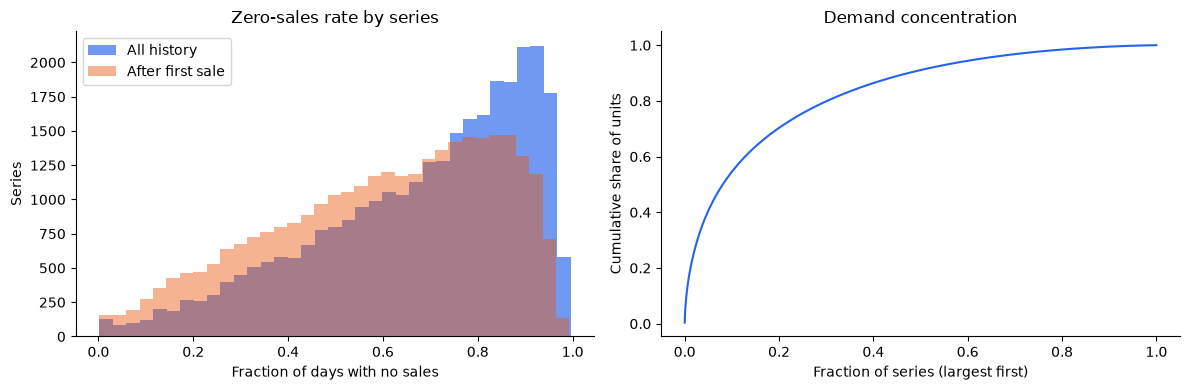

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(profile.zero_rate, bins=35, alpha=.65, label='All history', color=COLORS[0])
axes[0].hist(profile.active_zero_rate.dropna(), bins=35, alpha=.45, label='After first sale', color=COLORS[2])
axes[0].set(title='Zero-sales rate by series', xlabel='Fraction of days with no sales', ylabel='Series')
axes[0].legend()
share = profile.units.sort_values(ascending=False).cumsum().to_numpy() / profile.units.sum()
axes[1].plot(np.arange(1, len(share) + 1) / len(share), share, color=COLORS[0])
axes[1].set(title='Demand concentration', xlabel='Fraction of series (largest first)', ylabel='Cumulative share of units')
save_figure(data, 'eda_04_intermittency')


In [29]:
display(profile[['mean_daily', 'zero_rate', 'active_zero_rate']].describe())


,mean_daily,zero_rate,active_zero_rate
count,30490.000000,30490.000000,30490.000000
mean,1.126322,0.681963,0.601163
std,2.727249,0.223773,0.234028
min,0.005227,0.001568,0.001568
25%,0.185572,0.536853,0.432011
50%,0.443283,0.735494,0.634317
75%,1.062075,0.867224,0.796548
max,130.947203,0.996341,0.993122


## Representative series

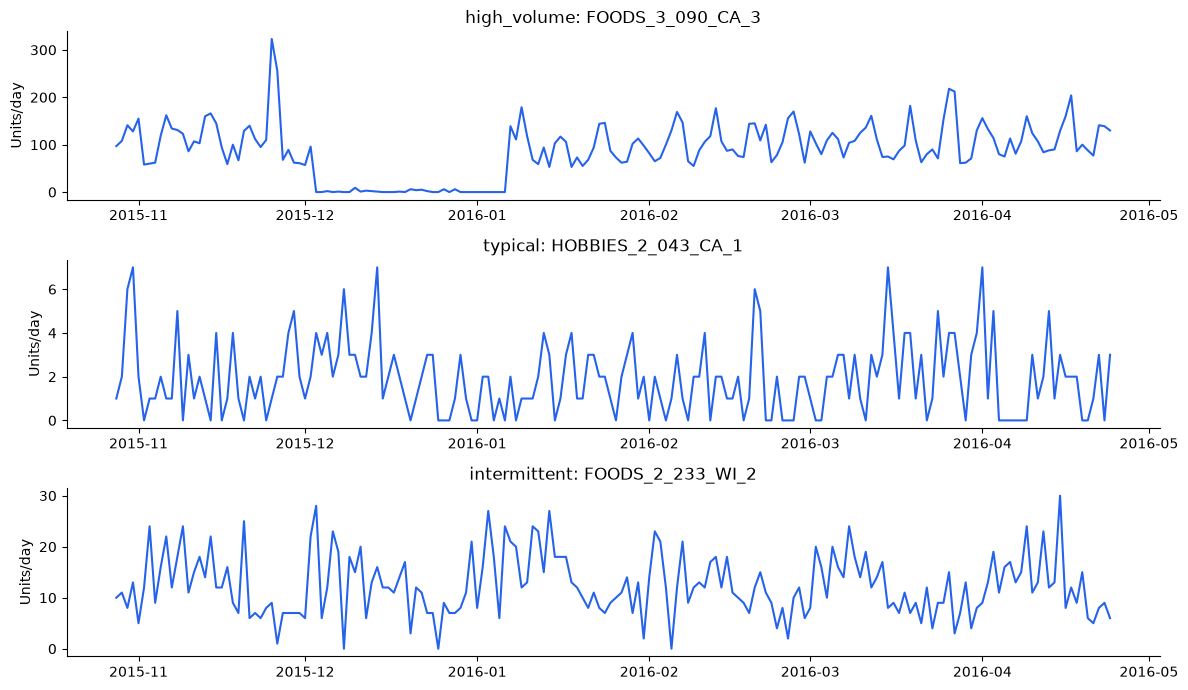

In [30]:
fig, axes = plt.subplots(3, 1, figsize=(12, 7))
dates = eda['daily'].date.iloc[-180:]
for ax, (label, row) in zip(axes, eda['representatives'].items()):
    ax.plot(dates, data.sales[row, eda['cutoff'] - 180:eda['cutoff']], color=COLORS[0])
    ax.set(title=f"{label}: {data.metadata.series_id.iloc[row]}", ylabel='Units/day')
save_figure(data, 'eda_05_example_series')


In [31]:
display(eda['profile'].loc[list(eda['representatives'].values()), ['series_id', 'mean_daily', 'zero_rate', 'active_zero_rate']])


,series_id,mean_daily,zero_rate,active_zero_rate
8412,FOODS_3_090_CA_3,130.947203,0.187663,0.187663
458,HOBBIES_2_043_CA_1,0.443283,0.786200,0.421499
26451,FOODS_2_233_WI_2,1.430737,0.877679,0.850000


## Event associations

In [32]:
daily = eda['daily'].copy()
daily['ratio'] = daily.units / daily.groupby(['year', 'wday']).units.transform('mean')
events = daily[['d', 'event_name_1', 'event_name_2']].melt(id_vars='d', value_name='event').dropna(subset=['event'])
events = events[['d', 'event']].drop_duplicates().merge(daily[['d', 'ratio']], on='d', validate='many_to_one')
summary = events.groupby('event').agg(days=('ratio', 'size'), weekday_year_ratio=('ratio', 'mean'))
summary = summary[summary.days >= 3].sort_values('weekday_year_ratio')


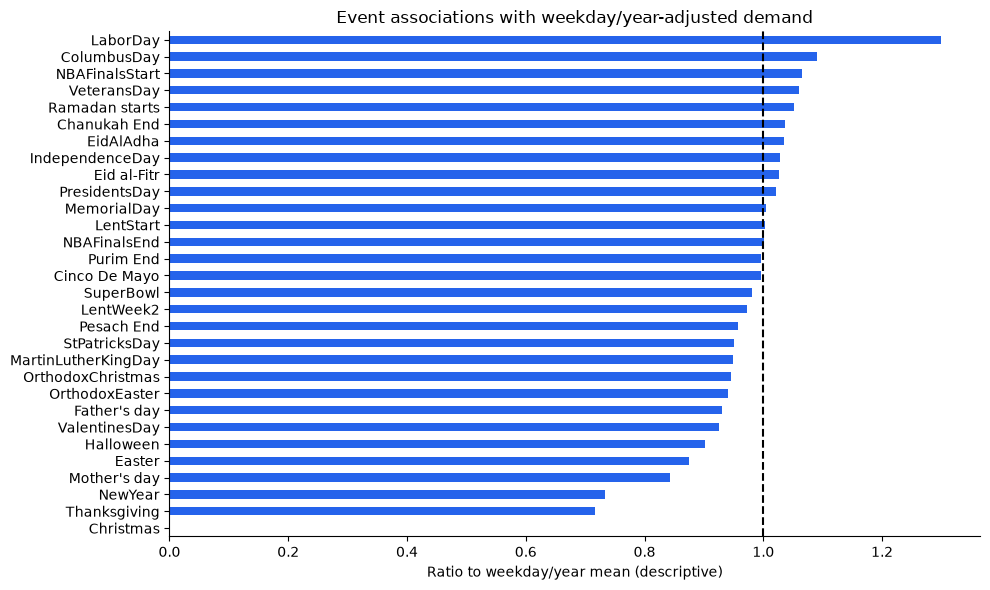

In [33]:
fig, ax = plt.subplots(figsize=(10, 6))
summary.weekday_year_ratio.plot.barh(ax=ax, color=COLORS[0])
ax.axvline(1, color='black', linestyle='--')
ax.set(title='Event associations with weekday/year-adjusted demand', xlabel='Ratio to weekday/year mean (descriptive)', ylabel='')
save_figure(data, 'eda_06_events')


In [34]:
display(summary)


,days,weekday_year_ratio
event,,
Christmas,5,0.000494
Thanksgiving,5,0.716223
NewYear,5,0.732804
Mother's day,5,0.842920
Easter,6,0.874039
Halloween,5,0.901904
ValentinesDay,6,0.925937
Father's day,5,0.930928
OrthodoxEaster,5,0.940838


## SNAP associations

In [35]:
rows = []
for state in ['CA', 'TX', 'WI']:
    daily = eda['daily'].copy()
    daily['units'] = eda['groups']['state_id'][state].to_numpy()
    daily['ratio'] = daily.units / daily.groupby(['year', 'wday']).units.transform('mean')
    for flag, group in daily.groupby('snap_' + state):
        rows.append(dict(state=state, snap=int(flag), days=len(group), demand_ratio=group.ratio.mean()))
summary = pd.DataFrame(rows)


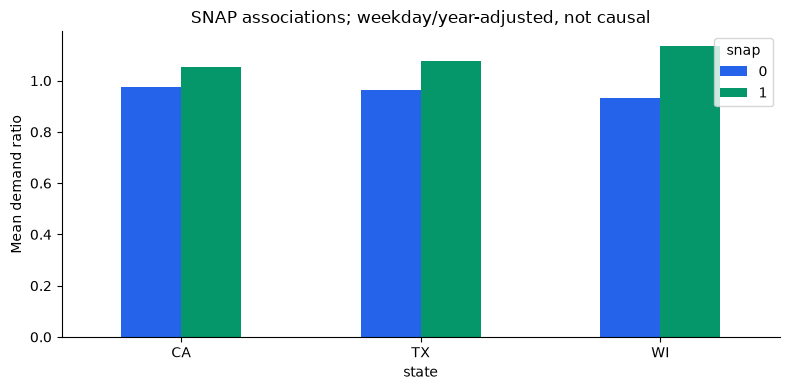

In [36]:
summary.pivot(index='state', columns='snap', values='demand_ratio').plot.bar(figsize=(8, 4), color=COLORS[:2])
plt.title('SNAP associations; weekday/year-adjusted, not causal')
plt.ylabel('Mean demand ratio')
plt.xticks(rotation=0)
save_figure(data, 'eda_07_snap')


In [37]:
display(summary)


,state,snap,days,demand_ratio
0,CA,0,1283,0.973447
1,CA,1,630,1.054076
2,TX,0,1283,0.962752
3,TX,1,630,1.075855
4,WI,0,1283,0.933361
5,WI,1,630,1.135710


## Price and demand relationships

In [38]:
rows = np.asarray(eda['sample_rows'])
cutoff = eda['cutoff']
start = max(0, cutoff - 365)
days = data.calendar.iloc[start:cutoff]
sample = pd.DataFrame(dict(row=np.repeat(rows, len(days)),
                           day=np.tile(days.day.to_numpy(), len(rows)),
                           sales=data.sales[rows, start:cutoff].reshape(-1),
                           price=data.prices[rows[:, None], days.week_index.to_numpy()].reshape(-1)))
sample['cat_id'] = data.metadata.cat_id.to_numpy()[sample.row]
sample['date'] = data.calendar.date.to_numpy()[sample.day - 1]
assert len(sample) == len(rows) * len(days)
missing = sample.price.isna()
eda['price_sample_missing_pct'] = float(missing.mean() * 100)


In [39]:
eda['sample_sales_without_price'] = int(((sample.sales > 0) & missing).sum())
correlations = []
for row, group in sample.dropna(subset=['price']).groupby('row'):
    if group.price.nunique() >= 3 and group.sales.nunique() > 1:
        correlations.append(dict(series_id=data.metadata.series_id.iloc[row], observations=len(group),
                                 price_levels=group.price.nunique(), spearman=group[['price', 'sales']].corr(method='spearman').iloc[0, 1]))
correlations = pd.DataFrame(correlations, columns=['series_id', 'observations', 'price_levels', 'spearman'])
eda['price_correlations'] = correlations


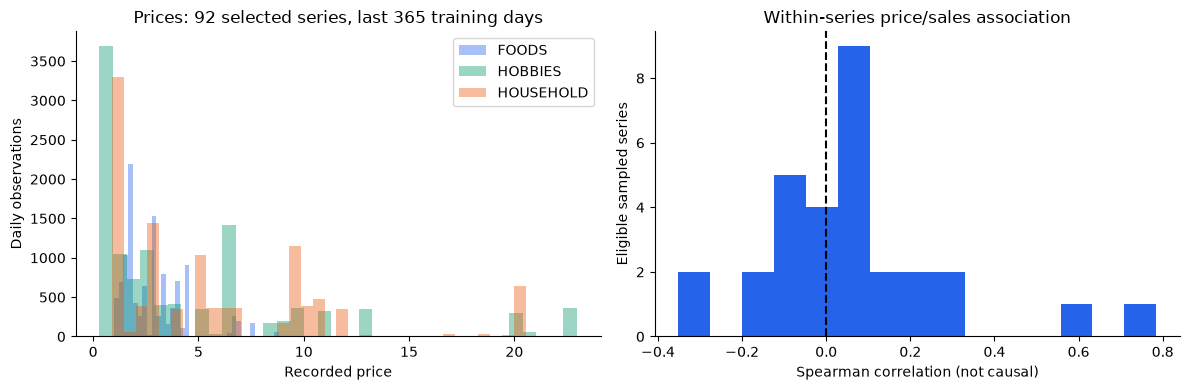

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, category in enumerate(sorted(sample.cat_id.unique())):
    prices = sample.loc[sample.cat_id == category, 'price'].dropna()
    axes[0].hist(prices, bins=35, alpha=.4, label=category, color=COLORS[i])
axes[0].set(title=f'Prices: {len(rows)} selected series, last 365 training days', xlabel='Recorded price', ylabel='Daily observations')
axes[0].legend()
axes[1].hist(correlations.spearman.dropna(), bins=15, color=COLORS[0])
axes[1].axvline(0, color='black', linestyle='--')
axes[1].set(title='Within-series price/sales association', xlabel='Spearman correlation (not causal)', ylabel='Eligible sampled series')
save_figure(data, 'eda_08_prices')


In [41]:
row = eda['representatives']['high_volume']
example = sample[sample.row == row]


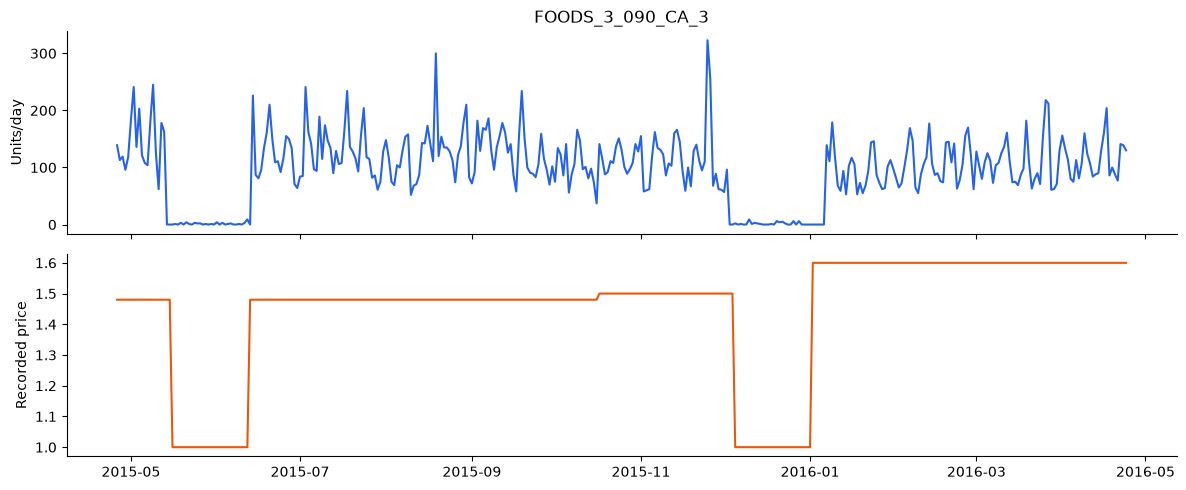

In [42]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].plot(example.date, example.sales, color=COLORS[0])
axes[0].set(title=data.metadata.series_id.iloc[row], ylabel='Units/day')
axes[1].plot(example.date, example.price, color=COLORS[2])
axes[1].set(ylabel='Recorded price')
save_figure(data, 'eda_09_price_and_sales')


In [43]:
display(pd.DataFrame(dict(
    sampled_series=[len(rows)],
    daily_rows=[len(sample)],
    missing_price_rows=[int(missing.sum())],
    positive_sales_without_price=[eda['sample_sales_without_price']],
    eligible_correlations=[len(correlations)],
    median_spearman=[correlations.spearman.median()])))


,sampled_series,daily_rows,missing_price_rows,positive_sales_without_price,eligible_correlations,median_spearman
0,92,33580,0,0,30,0.040888


## Key findings

In [44]:
profile = eda['profile']
facts = dict(series=len(profile), training_days=eda['cutoff'],
    zero_sales_percent=100*profile.zero_rate.mean(),
    detrended_weekly_correlation=eda['acf7'],
    price_sample_series=len(eda['sample_rows']))
display(pd.Series(facts).to_frame('finding'))


,finding
series,30490.000000
training_days,1913.000000
zero_sales_percent,68.196276
detrended_weekly_correlation,0.700873
price_sample_series,92.000000
